<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding How The Data Is Distributed**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis (EDA). You will examine the structure of the data, visualize key variables, and analyze trends related to developer experience, tools, job satisfaction, and other important aspects.


## Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.

- Perform summary statistics and data visualization.

- Identify trends in developer experience, tools, job satisfaction, and other key variables.


### Install the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.


- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [7]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Display the first few rows of the dataset
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [8]:
df.info()

print("\nDataset shape (rows, columns):", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.6 MB

Dataset shape (rows, columns): (65437, 114)

### Step 3: Handle Missing Data


- Identify missing values in the dataset.

- Impute or remove missing values as necessary to ensure data completeness.



In [9]:
key_columns = ['Employment', 'JobSat', 'YearsCodePro']
df = df.dropna(subset=key_columns)

print("Dataset dimensions after targeted cleaning (rows, columns):", df.shape)

Dataset dimensions after targeted cleaning (rows, columns): (28356, 114)

### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).

- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.



In [10]:
print("--- Employment Distribution ---")
print(df['Employment'].value_counts())

print("\n--- Job Satisfaction Distribution ---")
print(df['JobSat'].value_counts())

print("\n--- Professional Coding Experience Distribution ---")
print(df['YearsCodePro'].value_counts())

--- Employment Distribution ---
Employment
Employed, full-time                                                                                                                                                       21903
Employed, full-time;Independent contractor, freelancer, or self-employed                                                                                                   2231
Independent contractor, freelancer, or self-employed                                                                                                                       1242
Employed, part-time                                                                                                                                                         531
Employed, full-time;Student, part-time                                                                                                                                      488
                                                                             

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.

- Provide an interpretation of the plot, highlighting key trends in job satisfaction.


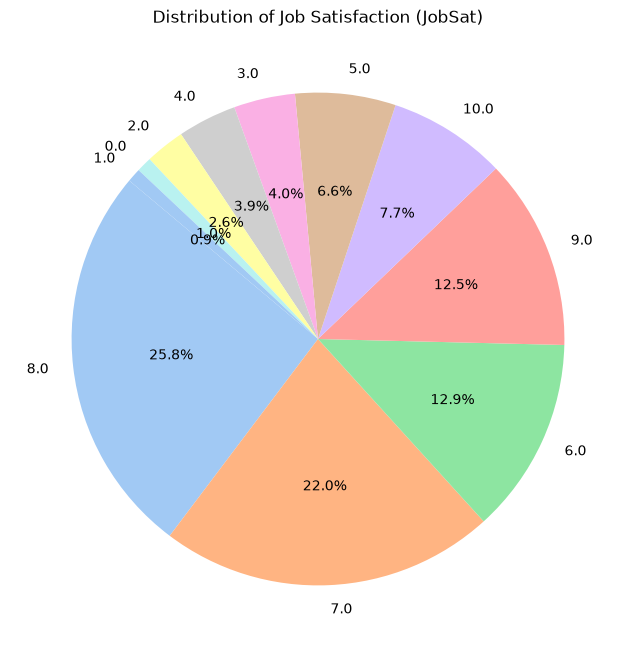

In [11]:
jobsat_counts = df['JobSat'].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    jobsat_counts, 
    labels=jobsat_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sns.color_palette('pastel')
)


plt.title('Distribution of Job Satisfaction (JobSat)')

plt.show()

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
  
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.


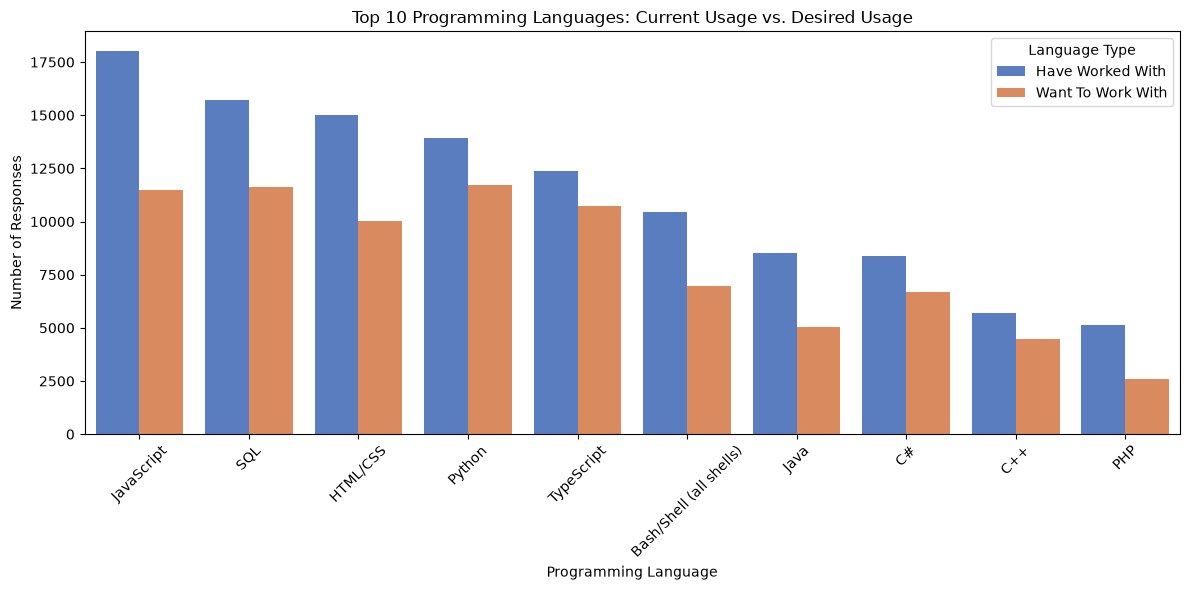

In [13]:
have_worked = df['LanguageHaveWorkedWith'].str.split(';').explode().value_counts()
want_worked = df['LanguageWantToWorkWith'].str.split(';').explode().value_counts()

lang_df = pd.DataFrame({'Have Worked With': have_worked, 'Want To Work With': want_worked})
top_10_langs = lang_df.sort_values(by='Have Worked With', ascending=False).head(10)

top_10_melted = top_10_langs.reset_index().melt(id_vars='index', var_name='Language Type', value_name='Count')

top_10_melted = top_10_melted.rename(columns={'index': 'Language'})

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_melted, x='Language', y='Count', hue='Language Type', palette='muted')
plt.title('Top 10 Programming Languages: Current Usage vs. Desired Usage')
plt.xlabel('Programming Language')
plt.ylabel('Number of Responses')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


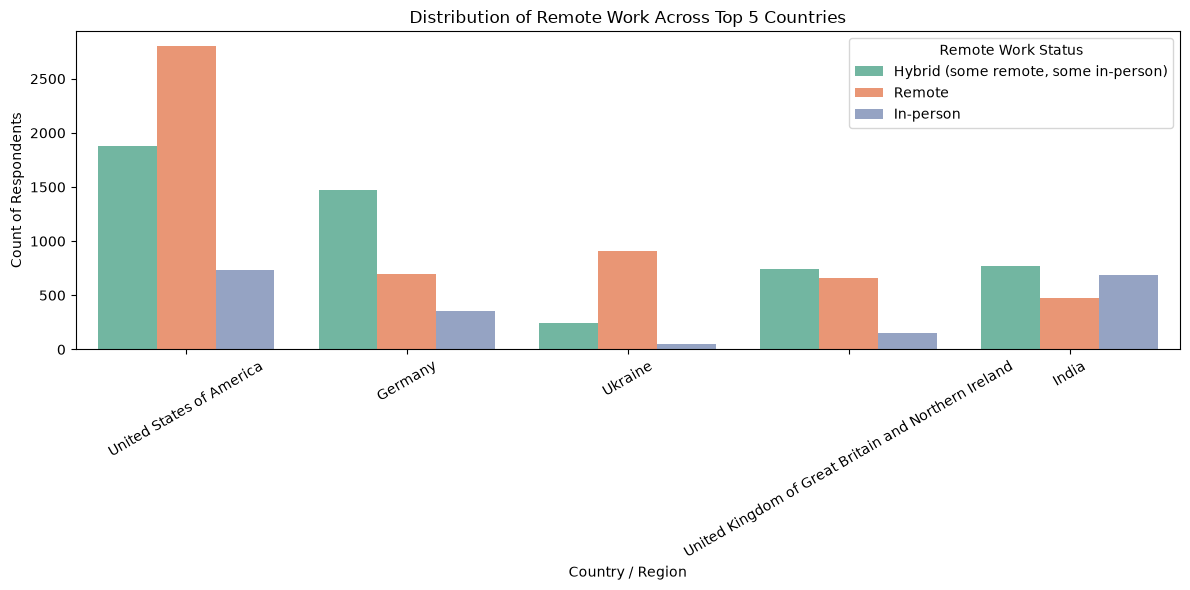

In [14]:
top_countries = df['Country'].value_counts().head(5).index
filtered_df = df[df['Country'].isin(top_countries)].copy()

plt.figure(figsize=(12, 6))
sns.countplot(data=filtered_df, x='Country', hue='RemoteWork', palette='Set2')
plt.title('Distribution of Remote Work Across Top 5 Countries')
plt.xlabel('Country / Region')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=30)
plt.legend(title='Remote Work Status')
plt.tight_layout()
plt.show()

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
  
- Calculate the Pearson or Spearman correlation coefficient.


In [15]:
import numpy as np

df.loc[:, 'YearsCodePro_numeric'] = df['YearsCodePro'].replace({'Less than 1 year': 0.5, 'More than 50 years': 51})
df.loc[:, 'YearsCodePro_numeric'] = pd.to_numeric(df['YearsCodePro_numeric'], errors='coerce')

jobsat_mapping = {
    'Very dissatisfied': 1,
    'Slightly dissatisfied': 2,
    'Neither satisfied nor dissatisfied': 3,
    'Slightly satisfied': 4,
    'Very satisfied': 5
}
df.loc[:, 'JobSat_numeric'] = df['JobSat'].map(jobsat_mapping)

correlation_data = df[['YearsCodePro_numeric', 'JobSat_numeric']].dropna()

spearman_corr = correlation_data['YearsCodePro_numeric'].corr(correlation_data['JobSat_numeric'], method='spearman')

print(f"Spearman correlation coefficient between Job Satisfaction and Experience: {spearman_corr:.4f}")

if abs(spearman_corr) < 0.1:
    print("Interpretation: There is negligible or no correlation between coding experience and job satisfaction.")
elif spearman_corr > 0:
    print("Interpretation: There is a positive correlation (more experienced developers tend to be more satisfied).")
else:
    print("Interpretation: There is a negative correlation (more experienced developers tend to be less satisfied).")

Spearman correlation coefficient between Job Satisfaction and Experience: nan
Interpretation: There is a negative correlation (more experienced developers tend to be less satisfied).

### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).

- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.


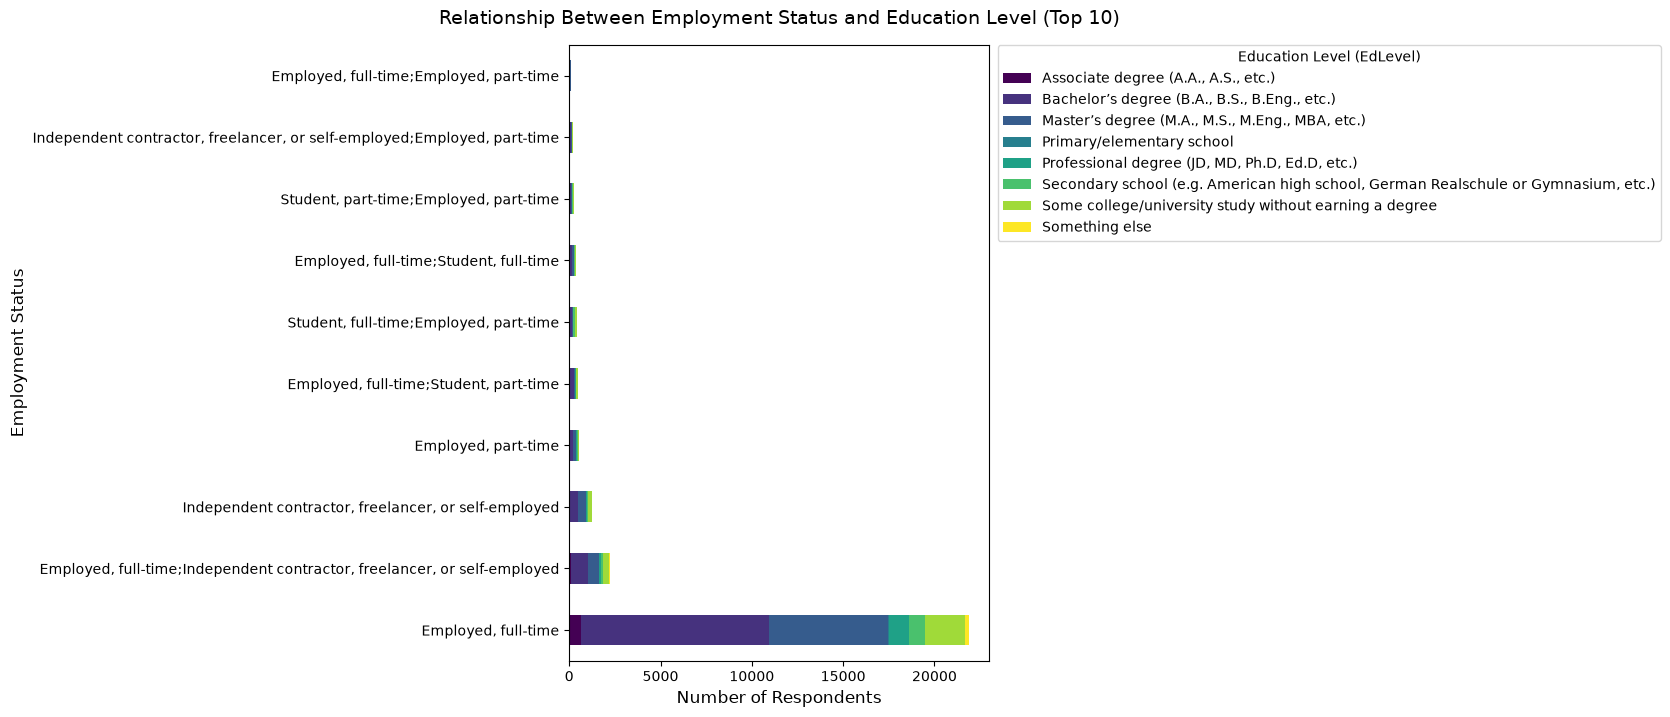

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

cross_tab = pd.crosstab(df['Employment'], df['EdLevel'])

top_employment = cross_tab.sum(axis=1).nlargest(10).index
cross_tab_filtered = cross_tab.loc[top_employment]

fig, ax = plt.subplots(figsize=(12, 8))
cross_tab_filtered.plot(kind='barh', stacked=True, ax=ax, colormap='viridis')

plt.title('Relationship Between Employment Status and Education Level (Top 10)', fontsize=14, pad=15)
plt.xlabel('Number of Respondents', fontsize=12)
plt.ylabel('Employment Status', fontsize=12)

plt.legend(title='Education Level (EdLevel)', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

plt.subplots_adjust(left=0.4, right=0.75)

plt.show()

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [19]:
output_filename = 'cleaned_survey_data.csv'

df.to_csv(output_filename, index=False)

print(f"Success! The cleaned dataset has been exported and saved as '{output_filename}'.")

Success! The cleaned dataset has been exported and saved as 'cleaned_survey_data.csv'.

### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:


- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.

- Identifying and addressing missing data to ensure the dataset's quality and completeness.

- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.

- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
      
    - Exploring remote work preferences by region.

- Investigating correlations between professional coding experience and job satisfaction.

- Performing cross-tabulations to analyze relationships between employment status and education levels.


## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
